# Explainable Machine Learning for Crime Hotspot Prediction
## Complete Python Analysis for Google Colab

This notebook implements the methodology proposed in dissertation.

**Study areas:** West Midlands Police and Warwickshire Police  
**Period:** June 2023 to April 2026  
**Models:** Random Forest and XGBoost  
**Explainability:** SHAP and LIME  
**Spatial unit:** LSOA by month  
**Main hotspot rule:** at or above the 80th percentile of monthly LSOA crime counts within each police force

The notebook is written so that the final CSV outputs can be imported directly into Power BI for Chapter 4.

### Research questions supported by this notebook

**RQ1:** To what extent can Random Forest and XGBoost predict crime hotspots, and how does performance differ between West Midlands and Warwickshire?

**RQ2:** Which spatial, temporal and crime-related features influence hotspot predictions, and how do SHAP and LIME explanations differ between models and force areas?

**RQ3:** How can the results be exported in a form suitable for an interactive Power BI dashboard?

## 1. Colab setup

Run this cell first. `lime` is not always preinstalled in Colab, so the notebook installs the required packages.

In [1]:
!pip -q install xgboost shap lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 3.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


## 2. Imports, settings and reproducibility

`FAST_MODE=True` uses a smaller hyperparameter search and fewer XAI cases. It is useful while checking that the full notebook runs correctly. For final dissertation results, change it to `False` and rerun the notebook from the top.

In [2]:
import os
import re
import json
import math
import random
import shutil
import zipfile
import warnings
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)
from sklearn.model_selection import ParameterSampler

from xgboost import XGBClassifier
import shap
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

FAST_MODE = True       # Set False for final dissertation run
HOTSPOT_QUANTILE = 0.80
TRAIN_END = '2025-06'
VAL_START, VAL_END = '2025-07', '2025-11'
TEST_START = '2025-12'

N_SEARCH_RF = 6 if FAST_MODE else 18
N_SEARCH_XGB = 6 if FAST_MODE else 18
SHAP_SAMPLE_SIZE = 1500 if FAST_MODE else 5000
LIME_CASES_PER_GROUP = 2 if FAST_MODE else 6
LIME_NUM_SAMPLES = 1500 if FAST_MODE else 5000

OUTPUT_DIR = Path('/content/crime_hotspot_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('FAST_MODE:', FAST_MODE)
print('Output folder:', OUTPUT_DIR)

FAST_MODE: True
Output folder: /content/crime_hotspot_outputs


## 3. Upload the police data ZIP file

Upload the supplied `Police_data(1).zip` or `Police_data.zip` file when prompted.

In [3]:
from google.colab import files

uploaded = files.upload()
zip_candidates = [name for name in uploaded.keys() if name.lower().endswith('.zip')]
if not zip_candidates:
    raise FileNotFoundError('No ZIP file was uploaded.')

ZIP_PATH = Path('/content') / zip_candidates[0]
print('Using:', ZIP_PATH)

Saving Police_data.zip to Police_data.zip
Using: /content/Police_data.zip


## 4. Read all monthly CSV files directly from the ZIP archive

The archive should contain 70 street-crime CSV files, 35 months for each force.

In [4]:
frames = []
file_audit = []

with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    csv_names = sorted([n for n in z.namelist() if n.lower().endswith('.csv')])
    print('CSV files found:', len(csv_names))

    for name in csv_names:
        temp = pd.read_csv(z.open(name), low_memory=False)
        force = 'Warwickshire' if 'warwickshire' in name.lower() else 'West Midlands'
        temp['_force'] = force
        temp['_source_file'] = name
        frames.append(temp)
        file_audit.append({
            'file': name,
            'force': force,
            'rows': len(temp),
            'month_in_file': temp['Month'].iloc[0] if len(temp) else None
        })

data_raw = pd.concat(frames, ignore_index=True)
file_audit = pd.DataFrame(file_audit)

print('Raw shape:', data_raw.shape)
print('Date range:', data_raw['Month'].min(), 'to', data_raw['Month'].max())
display(file_audit.groupby('force')['rows'].agg(['count','sum','min','max','mean']))

CSV files found: 70
Raw shape: (1121393, 14)
Date range: 2023-06 to 2026-04


,count,sum,min,max,mean
force,,,,,
Warwickshire,35,145146,3529,4991,4147.028571
West Midlands,35,976247,23783,31636,27892.771429


## 5. Initial dataset audit

This checks columns, missing data, crime categories and force totals. The results are also exported for the methodology and Power BI documentation.

In [5]:
audit_rows = []
for col in data_raw.columns:
    audit_rows.append({
        'column': col,
        'dtype': str(data_raw[col].dtype),
        'missing_n': int(data_raw[col].isna().sum()),
        'missing_pct': float(data_raw[col].isna().mean() * 100),
        'unique_nonmissing': int(data_raw[col].nunique(dropna=True))
    })

audit_df = pd.DataFrame(audit_rows).sort_values('missing_pct', ascending=False)
display(audit_df)

print('\nRows by force:')
display(data_raw['_force'].value_counts().rename('rows').to_frame())

print('\nCrime types:')
display(data_raw['Crime type'].value_counts().rename('rows').to_frame())

print('\nMissing Crime ID by crime type:')
missing_id_by_type = pd.crosstab(data_raw['Crime type'], data_raw['Crime ID'].isna())
missing_id_by_type.columns = ['Crime_ID_present', 'Crime_ID_missing']
display(missing_id_by_type)

audit_df.to_csv(OUTPUT_DIR / '01_column_audit.csv', index=False)
file_audit.to_csv(OUTPUT_DIR / '01_file_audit.csv', index=False)

,column,dtype,missing_n,missing_pct,unique_nonmissing
11,Context,float64,1121393,100.000000,0
0,Crime ID,object,97479,8.692671,1023903
10,Last outcome category,object,97479,8.692671,14
7,LSOA code,object,1235,0.110131,2613
4,Longitude,float64,1235,0.110131,35523
5,Latitude,float64,1235,0.110131,34449
8,LSOA name,object,1235,0.110131,2613
2,Reported by,object,0,0.000000,2
1,Month,object,0,0.000000,35
3,Falls within,object,0,0.000000,2



Rows by force:


,rows
_force,
West Midlands,976247
Warwickshire,145146



Crime types:


,rows
Crime type,
Violence and sexual offences,442442
Shoplifting,98499
Vehicle crime,97887
Anti-social behaviour,97479
Criminal damage and arson,84593
Other theft,70375
Public order,66009
Burglary,54614
Drugs,28029



Missing Crime ID by crime type:


,Crime_ID_present,Crime_ID_missing
Crime type,,
Anti-social behaviour,0,97479
Bicycle theft,6930,0
Burglary,54614,0
Criminal damage and arson,84593,0
Drugs,28029,0
Other crime,22310,0
Other theft,70375,0
Possession of weapons,20840,0
Public order,66009,0


## 6. Clean the dataset

The rules follow Chapter 3:

1. Remove rows without LSOA or coordinates because they cannot support spatial analysis.
2. Keep the stable local-authority prefixes that belong to the two force areas in this archive.
3. Retain anti-social behaviour even though Crime ID and outcome are missing.


In [6]:
data = data_raw.copy()

print('Raw rows:', len(data))

# 1. Remove records without coordinates
data = data.dropna(subset=['Longitude', 'Latitude'])

print('After removing missing coordinates:', len(data))

# 2. Keep only records inside the study area
data = data[
    (data['Latitude'] > 51.95) &
    (data['Latitude'] < 52.85) &
    (data['Longitude'] > -2.30) &
    (data['Longitude'] < -1.10)
].copy()

print('After study-area check:', len(data))

# 3. LSOA is required for our LSOA-month modelling
data = data.dropna(subset=['LSOA code', 'LSOA name'])

print('After checking LSOA information:', len(data))

# 4. Remove duplicate records only where Crime ID exists
has_id = data['Crime ID'].notna()
is_duplicate = data.duplicated(subset=['Crime ID'])

clean = data[~(has_id & is_duplicate)].copy()

print('After removing duplicates:', len(clean))

# 5. Create proper date column
clean['date'] = pd.to_datetime(clean['Month'] + '-01')

clean = clean.sort_values(
    ['_force', 'date', 'LSOA code']
).reset_index(drop=True)

# 6. Cleaning summary
cleaning_summary = pd.DataFrame({
    'stage': [
        'Raw rows',
        'After missing-coordinate removal',
        'After study-area check',
        'After LSOA check',
        'After duplicate removal'
    ],
    'rows': [
        len(data_raw),
        len(data_raw.dropna(subset=['Longitude', 'Latitude'])),
        len(
            data_raw.dropna(subset=['Longitude', 'Latitude']).query(
                "Latitude > 51.95 and Latitude < 52.85 and Longitude > -2.30 and Longitude < -1.10"
            )
        ),
        len(data),
        len(clean)
    ]
})

display(cleaning_summary)

print('Final LSOAs by force:')
display(
    clean.groupby('_force')['LSOA code']
    .nunique()
    .rename('LSOAs')
    .to_frame()
)

cleaning_summary.to_csv(
    OUTPUT_DIR / '02_cleaning_summary.csv',
    index=False
)

Raw rows: 1121393
After removing missing coordinates: 1120158
After study-area check: 1119798
After checking LSOA information: 1119798
After removing duplicates: 1119787


,stage,rows
0,Raw rows,1121393
1,After missing-coordinate removal,1120158
2,After study-area check,1119798
3,After LSOA check,1119798
4,After duplicate removal,1119787


Final LSOAs by force:


,LSOAs
_force,
Warwickshire,951
West Midlands,1760


## 7. Basic exploratory analysis

These descriptive outputs are useful for Chapter 4 and the Power BI dashboard. They do not determine the hotspot target yet.

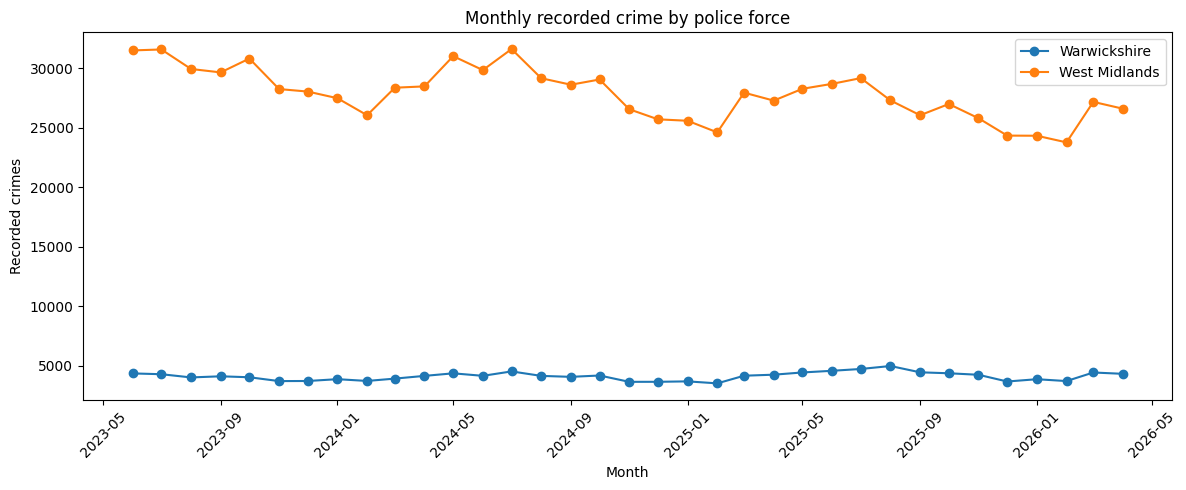

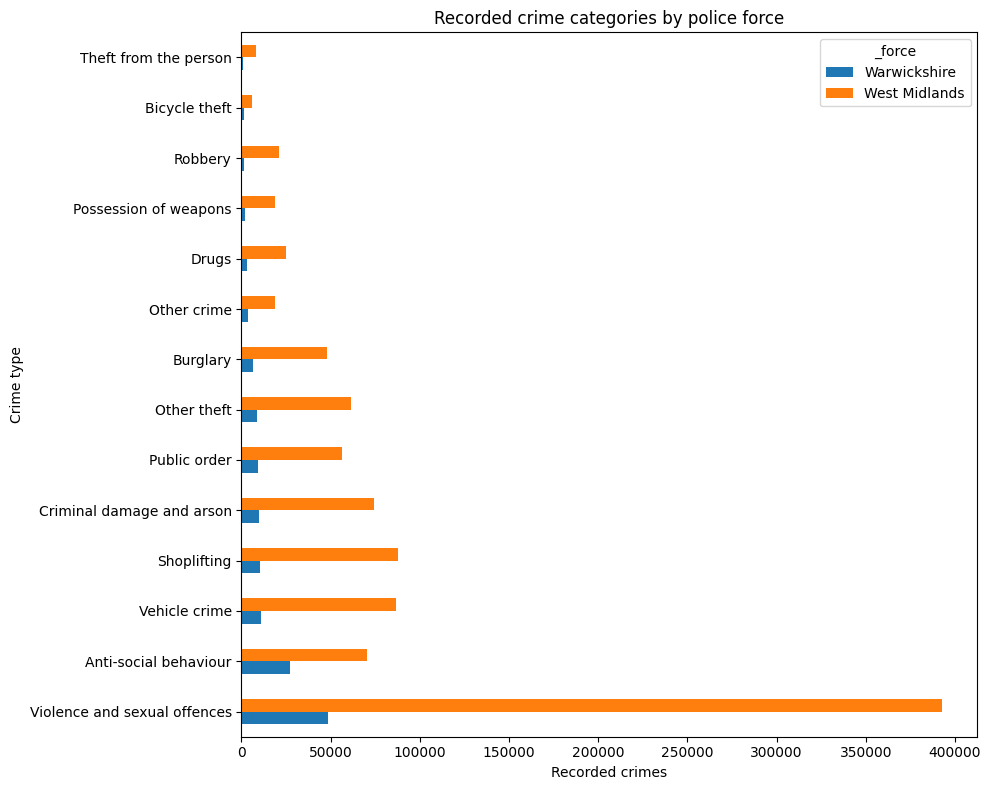

In [7]:
monthly_trends = (
    clean.groupby(['_force', 'Month'])
    .size().rename('crime_count').reset_index()
)
crime_type_totals = (
    clean.groupby(['_force', 'Crime type'])
    .size().rename('crime_count').reset_index()
)

monthly_trends.to_csv(OUTPUT_DIR / '03_monthly_crime_trends.csv', index=False)
crime_type_totals.to_csv(OUTPUT_DIR / '03_crime_type_totals.csv', index=False)

# Monthly trend chart
fig, ax = plt.subplots(figsize=(12,5))
for force, sub in monthly_trends.groupby('_force'):
    ax.plot(pd.to_datetime(sub['Month']), sub['crime_count'], marker='o', label=force)
ax.set_title('Monthly recorded crime by police force')
ax.set_xlabel('Month')
ax.set_ylabel('Recorded crimes')
ax.legend()
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_monthly_crime_trends.png', dpi=180, bbox_inches='tight')
plt.show()

# Crime type totals chart
pivot_ct = crime_type_totals.pivot(index='Crime type', columns='_force', values='crime_count').fillna(0)
pivot_ct = pivot_ct.sort_values(by=list(pivot_ct.columns), ascending=False)
ax = pivot_ct.plot(kind='barh', figsize=(10,8))
ax.set_title('Recorded crime categories by police force')
ax.set_xlabel('Recorded crimes')
ax.set_ylabel('Crime type')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_crime_type_totals.png', dpi=180, bbox_inches='tight')
plt.show()

## 8. Build the complete LSOA-month panel

A complete panel is important because an LSOA with zero recorded crime in a month should remain in the modelling data rather than disappear.

In [8]:
# Median coordinates provide one reference point per LSOA for mapping.
centroids = (
    clean.groupby(['_force', 'LSOA code'])[['Longitude', 'Latitude']]
    .median()
    .rename(columns={'Longitude':'centroid_lon', 'Latitude':'centroid_lat'})
    .reset_index()
)

# Total crime counts.
total_counts = (
    clean.groupby(['_force', 'LSOA code', 'Month'])
    .size().rename('crime_count').reset_index()
)

# Crime type counts.
crime_type_table = pd.crosstab(
    index=[clean['_force'], clean['LSOA code'], clean['Month']],
    columns=clean['Crime type']
).reset_index()

# Clean crime-type column names.
id_cols = ['_force', 'LSOA code', 'Month']
crime_type_cols = []
rename_map = {}
for col in crime_type_table.columns:
    if col in id_cols:
        continue
    safe = re.sub(r'[^A-Za-z0-9]+', '_', str(col).strip()).strip('_').lower()
    rename_map[col] = safe
    crime_type_cols.append(safe)
crime_type_table = crime_type_table.rename(columns=rename_map)

months = sorted(clean['Month'].unique())
lsoa_units = clean[['_force', 'LSOA code', 'LSOA name']].drop_duplicates(['_force', 'LSOA code'])

full_grids = []
for force, units in lsoa_units.groupby('_force'):
    temp = (
        units.assign(_key=1)
        .merge(pd.DataFrame({'Month': months, '_key':1}), on='_key')
        .drop(columns='_key')
    )
    full_grids.append(temp)

panel = pd.concat(full_grids, ignore_index=True)
panel = panel.merge(total_counts, on=['_force','LSOA code','Month'], how='left')
panel = panel.merge(crime_type_table, on=['_force','LSOA code','Month'], how='left')
panel = panel.merge(centroids, on=['_force','LSOA code'], how='left')

panel['crime_count'] = panel['crime_count'].fillna(0).astype(int)
panel[crime_type_cols] = panel[crime_type_cols].fillna(0).astype(int)
panel['date'] = pd.to_datetime(panel['Month'] + '-01')

print('Complete panel shape:', panel.shape)
print('Expected 72,555 rows with the supplied archive.')
display(panel.groupby('_force')['LSOA code'].nunique().rename('LSOAs').to_frame())

Complete panel shape: (94885, 22)
Expected 72,555 rows with the supplied archive.


,LSOAs
_force,
Warwickshire,951
West Midlands,1760


## 9. Create the hotspot target

An LSOA is a hotspot when its current-month crime count is at or above the 80th percentile within the same force and month. The current count creates the target only. It is never used as a predictor for the same month.

In [9]:
panel['hotspot_threshold'] = panel.groupby(['_force','Month'])['crime_count'].transform(
    lambda s: s.quantile(HOTSPOT_QUANTILE)
)
panel['hotspot'] = (panel['crime_count'] >= panel['hotspot_threshold']).astype(int)

class_balance = (
    panel.groupby(['_force','Month'])['hotspot']
    .mean().reset_index(name='hotspot_share')
)

print('Overall hotspot share by force:')
display(panel.groupby('_force')['hotspot'].mean().rename('hotspot_share').to_frame())

class_balance.to_csv(OUTPUT_DIR / '04_hotspot_class_balance.csv', index=False)

Overall hotspot share by force:


,hotspot_share
_force,
Warwickshire,0.211116
West Midlands,0.208019


## 10. Feature engineering without target leakage

All dynamic predictors use information from earlier months only.

**Features created:**

- median LSOA latitude and longitude
- annual month sine and cosine terms
- linear time index
- total crime lags for 1, 2 and 3 months
- previous three-month rolling mean and standard deviation
- previous-month hotspot status
- previous-month counts for all 14 crime categories

In [10]:
panel['month_of_year'] = panel['date'].dt.month
panel['time_index'] = (
    (panel['date'].dt.year - panel['date'].dt.year.min()) * 12
    + panel['date'].dt.month - panel['date'].dt.month.min()
)
panel['month_sin'] = np.sin(2 * np.pi * panel['month_of_year'] / 12)
panel['month_cos'] = np.cos(2 * np.pi * panel['month_of_year'] / 12)

panel = panel.sort_values(['_force','LSOA code','date']).reset_index(drop=True)
grp = panel.groupby(['_force','LSOA code'], group_keys=False)

for lag in [1,2,3]:
    panel[f'crime_count_lag{lag}'] = grp['crime_count'].shift(lag)

panel['crime_roll3_mean'] = grp['crime_count'].transform(
    lambda s: s.shift(1).rolling(3, min_periods=3).mean()
)
panel['crime_roll3_std'] = grp['crime_count'].transform(
    lambda s: s.shift(1).rolling(3, min_periods=3).std()
)
panel['prev_hotspot'] = grp['hotspot'].shift(1)

for col in crime_type_cols:
    panel[f'{col}_lag1'] = grp[col].shift(1)

required_history = [
    'crime_count_lag1','crime_count_lag2','crime_count_lag3',
    'crime_roll3_mean','crime_roll3_std','prev_hotspot'
]
model_df = panel.dropna(subset=required_history).copy()

FEATURE_COLS = [
    'centroid_lon','centroid_lat','time_index','month_sin','month_cos',
    'crime_count_lag1','crime_count_lag2','crime_count_lag3',
    'crime_roll3_mean','crime_roll3_std','prev_hotspot'
] + [f'{c}_lag1' for c in crime_type_cols]

print('Model-ready shape:', model_df.shape)
print('Number of predictors:', len(FEATURE_COLS))
print('Model period:', model_df['Month'].min(), 'to', model_df['Month'].max())
print('\nFeatures:')
for f in FEATURE_COLS:
    print(' -', f)

model_df.to_csv(OUTPUT_DIR / '05_model_ready_panel.csv', index=False)

Model-ready shape: (86752, 48)
Number of predictors: 25
Model period: 2023-09 to 2026-04

Features:
 - centroid_lon
 - centroid_lat
 - time_index
 - month_sin
 - month_cos
 - crime_count_lag1
 - crime_count_lag2
 - crime_count_lag3
 - crime_roll3_mean
 - crime_roll3_std
 - prev_hotspot
 - anti_social_behaviour_lag1
 - bicycle_theft_lag1
 - burglary_lag1
 - criminal_damage_and_arson_lag1
 - drugs_lag1
 - other_crime_lag1
 - other_theft_lag1
 - possession_of_weapons_lag1
 - public_order_lag1
 - robbery_lag1
 - shoplifting_lag1
 - theft_from_the_person_lag1
 - vehicle_crime_lag1
 - violence_and_sexual_offences_lag1


## 11. Time-based train, validation and test split

The split is deliberately chronological:

- **Training:** September 2023 to June 2025
- **Validation:** July 2025 to November 2025
- **Test:** December 2025 to April 2026

The test period remains untouched until the final model is selected.

In [11]:
def split_force_data(df_force):
    train = df_force[df_force['Month'] <= TRAIN_END].copy()
    val = df_force[(df_force['Month'] >= VAL_START) & (df_force['Month'] <= VAL_END)].copy()
    test = df_force[df_force['Month'] >= TEST_START].copy()
    return train, val, test

split_summary = []
for force, sub in model_df.groupby('_force'):
    tr, va, te = split_force_data(sub)
    split_summary.extend([
        {'force':force, 'split':'train', 'rows':len(tr), 'months':tr['Month'].nunique(), 'hotspot_share':tr['hotspot'].mean()},
        {'force':force, 'split':'validation', 'rows':len(va), 'months':va['Month'].nunique(), 'hotspot_share':va['hotspot'].mean()},
        {'force':force, 'split':'test', 'rows':len(te), 'months':te['Month'].nunique(), 'hotspot_share':te['hotspot'].mean()},
    ])

split_summary = pd.DataFrame(split_summary)
display(split_summary)
split_summary.to_csv(OUTPUT_DIR / '06_split_summary.csv', index=False)

,force,split,rows,months,hotspot_share
0,Warwickshire,train,20922,22,0.212265
1,Warwickshire,validation,4755,5,0.209674
2,Warwickshire,test,4755,5,0.207150
3,West Midlands,train,38720,22,0.208032
4,West Midlands,validation,8800,5,0.205682
5,West Midlands,test,8800,5,0.207727


## 12. Evaluation helper functions

In [12]:
def metric_dict(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'roc_auc': roc_auc_score(y_true, y_prob),
        'pr_auc': average_precision_score(y_true, y_prob),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)
    }


def validate_model(model, X_train, y_train, X_val, y_val):
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    prob = model.predict_proba(X_val)[:,1]
    return metric_dict(y_val, pred, prob)

## 13. Hyperparameter search

The search uses the validation months rather than random cross-validation. Candidate settings are sampled with a fixed seed. The best candidate is selected by validation F1-score.

In [13]:
RF_SPACE = {
    'n_estimators': [250, 400, 600],
    'max_depth': [None, 12, 20, 30],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 0.5, 0.8]
}

XGB_SPACE = {
    'n_estimators': [250, 400, 600],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.03, 0.05, 0.08, 0.10],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0],
    'min_child_weight': [1, 3, 5]
}


def tune_force(force, df_force):
    train, val, test = split_force_data(df_force)
    X_train, y_train = train[FEATURE_COLS], train['hotspot']
    X_val, y_val = val[FEATURE_COLS], val['hotspot']

    search_rows = []

    # Random Forest
    rf_candidates = list(ParameterSampler(RF_SPACE, n_iter=N_SEARCH_RF, random_state=SEED))
    best_rf = None
    best_rf_score = -1
    best_rf_params = None

    for i, params in enumerate(rf_candidates, start=1):
        model = RandomForestClassifier(
            random_state=SEED,
            n_jobs=-1,
            class_weight='balanced_subsample',
            **params
        )
        m = validate_model(model, X_train, y_train, X_val, y_val)
        search_rows.append({'force':force, 'model':'Random Forest', 'candidate':i, **params, **m})
        if m['f1'] > best_rf_score:
            best_rf_score = m['f1']
            best_rf_params = params.copy()
            best_rf = model

    # XGBoost
    neg = int((y_train == 0).sum())
    pos = int((y_train == 1).sum())
    scale_pos_weight = neg / max(pos, 1)

    xgb_candidates = list(ParameterSampler(XGB_SPACE, n_iter=N_SEARCH_XGB, random_state=SEED))
    best_xgb = None
    best_xgb_score = -1
    best_xgb_params = None

    for i, params in enumerate(xgb_candidates, start=1):
        model = XGBClassifier(
            objective='binary:logistic',
            eval_metric='logloss',
            tree_method='hist',
            random_state=SEED,
            n_jobs=-1,
            scale_pos_weight=scale_pos_weight,
            reg_lambda=1.0,
            **params
        )
        m = validate_model(model, X_train, y_train, X_val, y_val)
        search_rows.append({'force':force, 'model':'XGBoost', 'candidate':i, **params, **m})
        if m['f1'] > best_xgb_score:
            best_xgb_score = m['f1']
            best_xgb_params = params.copy()
            best_xgb = model

    return {
        'train': train, 'val': val, 'test': test,
        'best_rf_params': best_rf_params,
        'best_xgb_params': best_xgb_params,
        'search_results': pd.DataFrame(search_rows)
    }

## 14. Tune models for both force areas

This is one of the slower sections. In `FAST_MODE` the search is intentionally small.

In [14]:
tuning = {}
search_results_all = []

for force in ['Warwickshire', 'West Midlands']:
    print('\nTuning:', force)
    result = tune_force(force, model_df[model_df['_force'] == force].copy())
    tuning[force] = result
    search_results_all.append(result['search_results'])
    print('Best Random Forest:', result['best_rf_params'])
    print('Best XGBoost:', result['best_xgb_params'])

search_results_all = pd.concat(search_results_all, ignore_index=True)
search_results_all.to_csv(OUTPUT_DIR / '07_hyperparameter_search.csv', index=False)


Tuning: Warwickshire
Best Random Forest: {'n_estimators': 600, 'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 20}
Best XGBoost: {'subsample': 0.9, 'n_estimators': 600, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 1.0}

Tuning: West Midlands
Best Random Forest: {'n_estimators': 600, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 20}
Best XGBoost: {'subsample': 0.9, 'n_estimators': 600, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


## 15. Refit the best models and evaluate on the untouched test months

In [15]:
model_store = {}
metrics_rows = []
confusion_rows = []
prediction_rows = []
best_params_rows = []

for force, info in tuning.items():
    train_val = pd.concat([info['train'], info['val']], ignore_index=True)
    test = info['test'].copy()

    X_train_val = train_val[FEATURE_COLS]
    y_train_val = train_val['hotspot']
    X_test = test[FEATURE_COLS]
    y_test = test['hotspot']

    model_specs = []

    rf = RandomForestClassifier(
        random_state=SEED, n_jobs=-1, class_weight='balanced_subsample',
        **info['best_rf_params']
    )
    model_specs.append(('Random Forest', rf, info['best_rf_params']))

    neg = int((y_train_val == 0).sum())
    pos = int((y_train_val == 1).sum())
    xgb = XGBClassifier(
        objective='binary:logistic', eval_metric='logloss', tree_method='hist',
        random_state=SEED, n_jobs=-1,
        scale_pos_weight=neg/max(pos,1), reg_lambda=1.0,
        **info['best_xgb_params']
    )
    model_specs.append(('XGBoost', xgb, info['best_xgb_params']))

    for model_name, model, params in model_specs:
        print('Fitting final:', force, model_name)
        model.fit(X_train_val, y_train_val)
        pred = model.predict(X_test)
        prob = model.predict_proba(X_test)[:,1]
        m = metric_dict(y_test, pred, prob)
        metrics_rows.append({'force':force, 'model':model_name, **m})
        best_params_rows.append({'force':force, 'model':model_name, 'parameters':json.dumps(params)})

        for label, value in [('TN',m['tn']),('FP',m['fp']),('FN',m['fn']),('TP',m['tp'])]:
            confusion_rows.append({'force':force, 'model':model_name, 'cell':label, 'count':value})

        pred_df = test[[
            '_force','LSOA code','LSOA name','Month','centroid_lon','centroid_lat',
            'crime_count','hotspot_threshold','hotspot'
        ]].copy()
        pred_df['model'] = model_name
        pred_df['predicted_hotspot'] = pred.astype(int)
        pred_df['predicted_probability'] = prob
        prediction_rows.append(pred_df)

        model_store[(force, model_name)] = {
            'model': model,
            'train_val': train_val,
            'test': test,
            'X_train_val': X_train_val,
            'X_test': X_test,
            'y_test': y_test,
            'pred': pred,
            'prob': prob
        }

metrics_df = pd.DataFrame(metrics_rows)
confusion_df = pd.DataFrame(confusion_rows)
predictions_df = pd.concat(prediction_rows, ignore_index=True)
best_params_df = pd.DataFrame(best_params_rows)

display(metrics_df[['force','model','precision','recall','f1','roc_auc','pr_auc','accuracy']])

metrics_df.to_csv(OUTPUT_DIR / '08_model_metrics.csv', index=False)
confusion_df.to_csv(OUTPUT_DIR / '08_confusion_matrix.csv', index=False)
predictions_df.to_csv(OUTPUT_DIR / '08_test_predictions.csv', index=False)
best_params_df.to_csv(OUTPUT_DIR / '08_best_hyperparameters.csv', index=False)

Fitting final: Warwickshire Random Forest
Fitting final: Warwickshire XGBoost
Fitting final: West Midlands Random Forest
Fitting final: West Midlands XGBoost


,force,model,precision,recall,f1,roc_auc,pr_auc,accuracy
0,Warwickshire,Random Forest,0.812757,0.802030,0.807358,0.972971,0.898668,0.920715
1,Warwickshire,XGBoost,0.760692,0.848731,0.802303,0.971495,0.894246,0.913354
2,West Midlands,Random Forest,0.773935,0.685449,0.727009,0.937263,0.837511,0.893068
3,West Midlands,XGBoost,0.652294,0.777899,0.709581,0.929895,0.818721,0.867727


## 16. Model-performance charts for Chapter 4

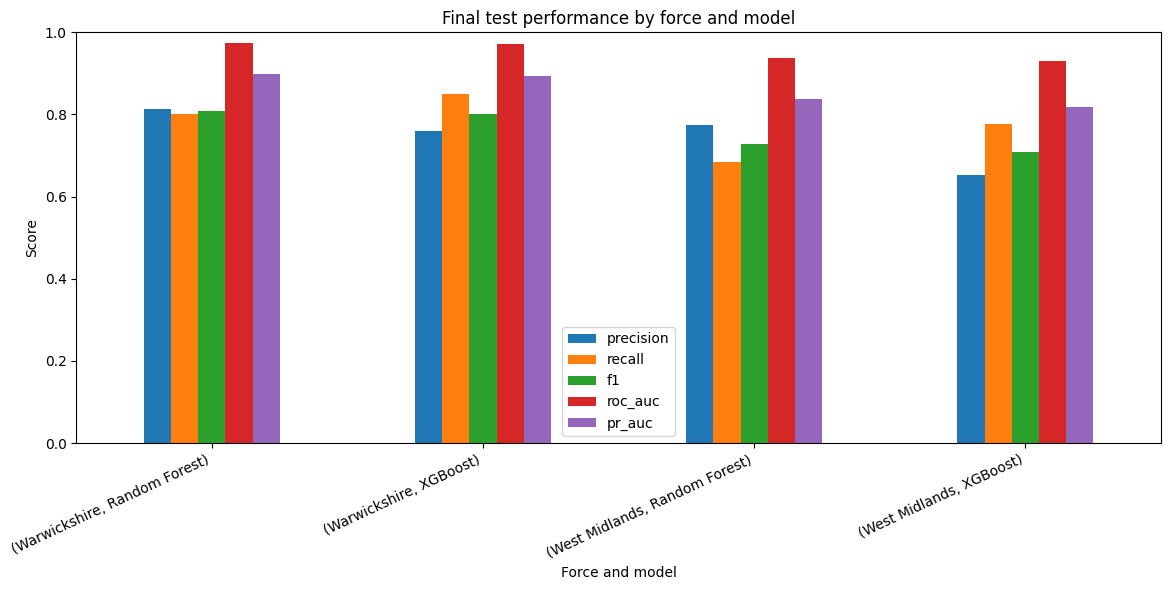

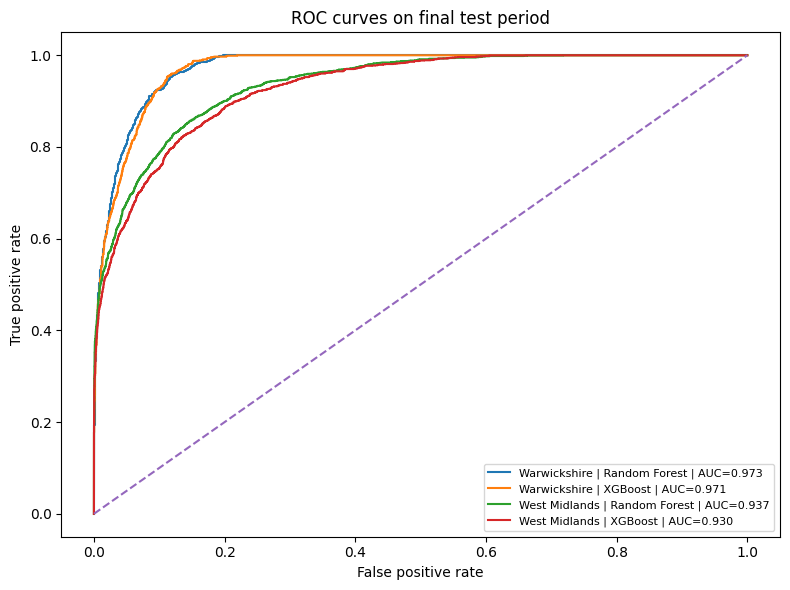

In [16]:
metric_names = ['precision','recall','f1','roc_auc','pr_auc']
plot_df = metrics_df.set_index(['force','model'])[metric_names]
ax = plot_df.plot(kind='bar', figsize=(12,6))
ax.set_ylim(0,1)
ax.set_title('Final test performance by force and model')
ax.set_ylabel('Score')
ax.set_xlabel('Force and model')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_model_metrics.png', dpi=180, bbox_inches='tight')
plt.show()

# ROC curves
fig, ax = plt.subplots(figsize=(8,6))
for (force, model_name), info in model_store.items():
    fpr, tpr, _ = roc_curve(info['y_test'], info['prob'])
    auc = roc_auc_score(info['y_test'], info['prob'])
    ax.plot(fpr, tpr, label=f'{force} | {model_name} | AUC={auc:.3f}')
ax.plot([0,1],[0,1], linestyle='--')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('ROC curves on final test period')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_roc_curves.png', dpi=180, bbox_inches='tight')
plt.show()

## 17. Global SHAP analysis

SHAP is calculated on a reproducible sample of the test set. The output is exported in long format for Power BI.

In [17]:
def positive_class_shap_values(explanation_values):
    vals = np.asarray(explanation_values)
    # Some binary classifiers return [samples, features, classes].
    if vals.ndim == 3:
        return vals[:, :, 1]
    return vals

shap_global_rows = []
shap_objects = {}

for (force, model_name), info in model_store.items():
    model = info['model']
    X_test = info['X_test']
    n = min(SHAP_SAMPLE_SIZE, len(X_test))
    X_sample = X_test.sample(n=n, random_state=SEED)

    print('SHAP:', force, model_name, '| sample:', len(X_sample))
    explainer = shap.TreeExplainer(model)
    explanation = explainer(X_sample)
    values = positive_class_shap_values(explanation.values)

    mean_abs = np.abs(values).mean(axis=0)
    for feature, importance in zip(FEATURE_COLS, mean_abs):
        shap_global_rows.append({
            'force':force, 'model':model_name,
            'feature':feature, 'mean_abs_shap':float(importance)
        })

    shap_objects[(force, model_name)] = {
        'explainer':explainer,
        'X_sample':X_sample,
        'values':values
    }

shap_global_df = pd.DataFrame(shap_global_rows)
shap_global_df['rank'] = shap_global_df.groupby(['force','model'])['mean_abs_shap'].rank(
    method='dense', ascending=False
)
shap_global_df = shap_global_df.sort_values(['force','model','rank'])
display(shap_global_df.groupby(['force','model']).head(10))
shap_global_df.to_csv(OUTPUT_DIR / '09_shap_global_importance.csv', index=False)

SHAP: Warwickshire Random Forest | sample: 1500
SHAP: Warwickshire XGBoost | sample: 1500
SHAP: West Midlands Random Forest | sample: 1500
SHAP: West Midlands XGBoost | sample: 1500


,force,model,feature,mean_abs_shap,rank
8,Warwickshire,Random Forest,crime_roll3_mean,0.283976,1.0
5,Warwickshire,Random Forest,crime_count_lag1,0.046307,2.0
7,Warwickshire,Random Forest,crime_count_lag3,0.030287,3.0
2,Warwickshire,Random Forest,time_index,0.024278,4.0
6,Warwickshire,Random Forest,crime_count_lag2,0.022891,5.0
0,Warwickshire,Random Forest,centroid_lon,0.013108,6.0
9,Warwickshire,Random Forest,crime_roll3_std,0.011429,7.0
1,Warwickshire,Random Forest,centroid_lat,0.010849,8.0
10,Warwickshire,Random Forest,prev_hotspot,0.007358,9.0
24,Warwickshire,Random Forest,violence_and_sexual_offences_lag1,0.006777,10.0


## 18. SHAP summary plots

The plots are saved for possible use in Chapter 4.

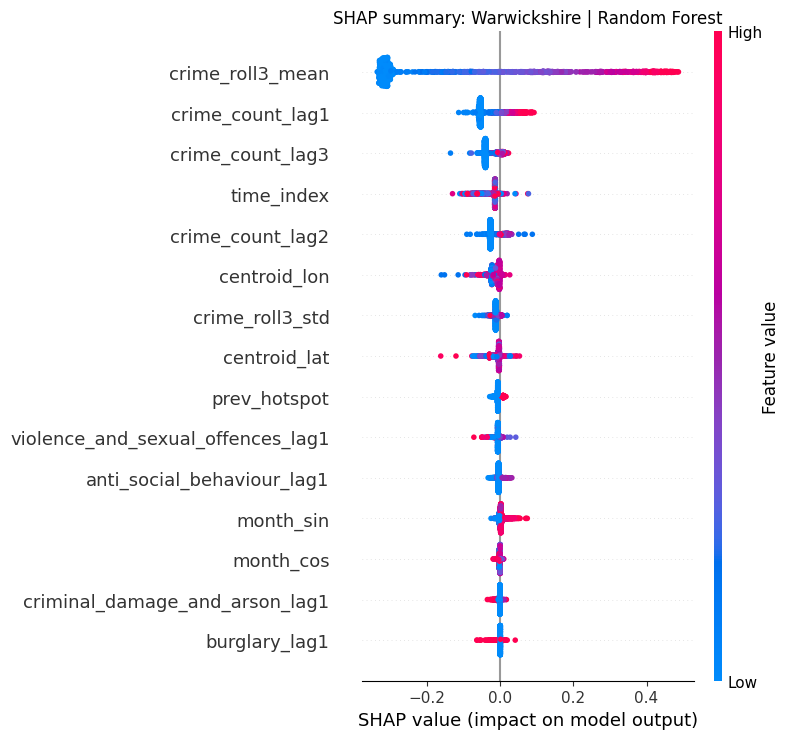

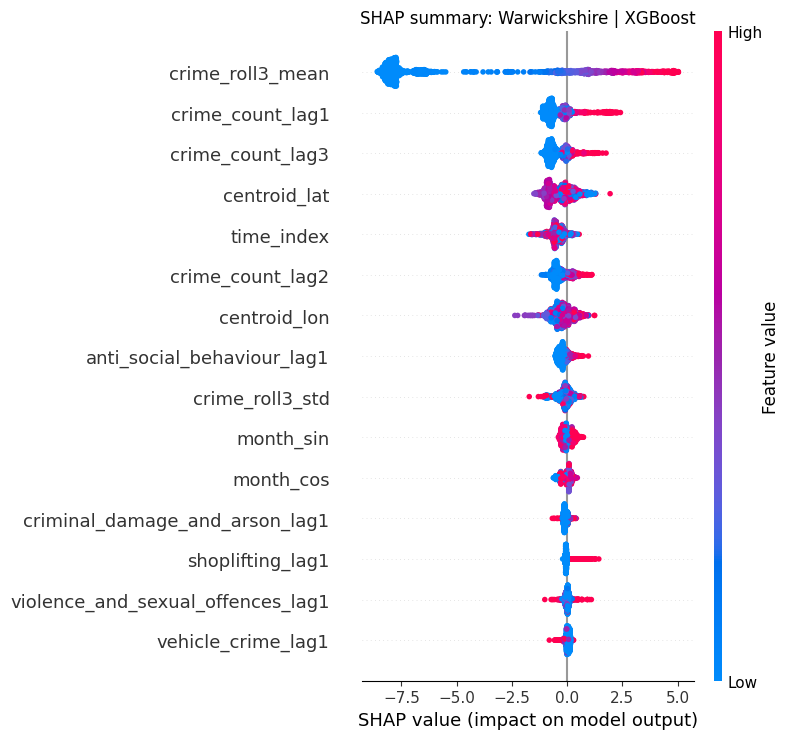

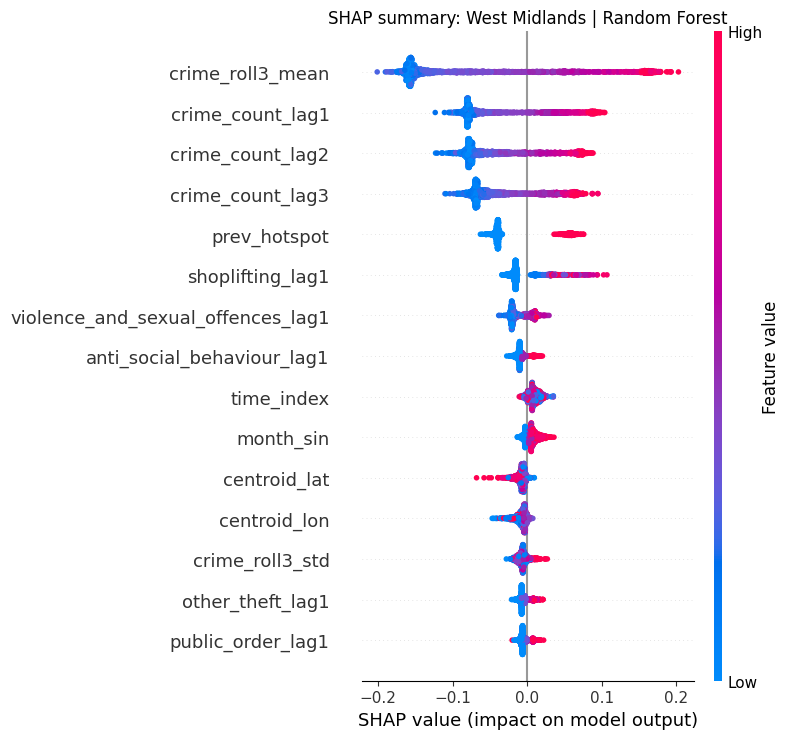

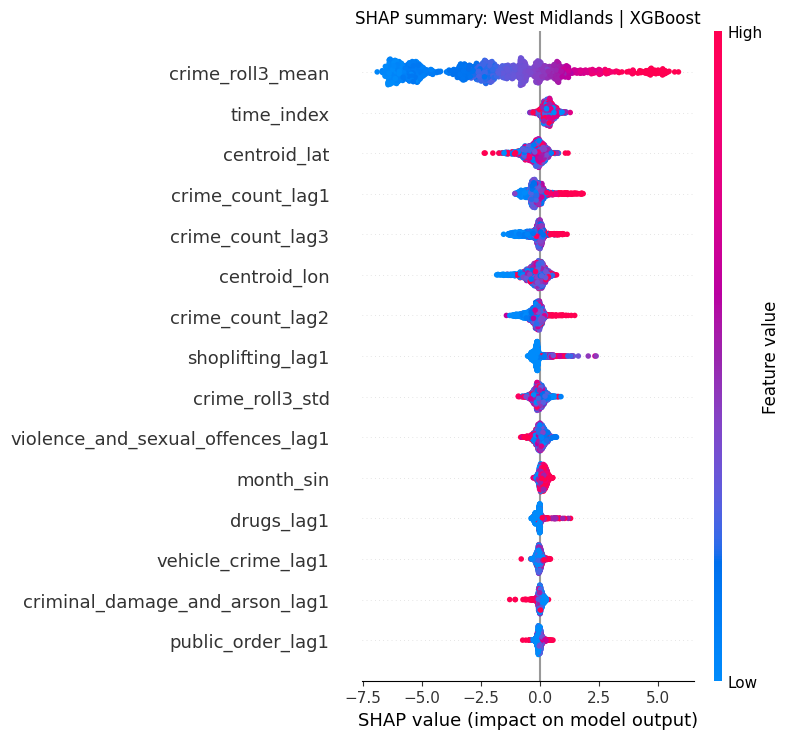

In [18]:
for (force, model_name), obj in shap_objects.items():
    plt.figure()
    shap.summary_plot(
        obj['values'], obj['X_sample'], feature_names=FEATURE_COLS,
        show=False, max_display=15
    )
    plt.title(f'SHAP summary: {force} | {model_name}')
    plt.tight_layout()
    safe = re.sub(r'[^A-Za-z0-9]+','_',f'{force}_{model_name}').strip('_').lower()
    plt.savefig(OUTPUT_DIR / f'fig_shap_summary_{safe}.png', dpi=180, bbox_inches='tight')


## 19. Select representative local cases

Cases are sampled from true positives, true negatives, false positives and false negatives so that SHAP and LIME are not compared only on easy predictions.

In [19]:
def add_confusion_group(y_true, y_pred):
    out = np.empty(len(y_true), dtype=object)
    for i, (yt, yp) in enumerate(zip(y_true, y_pred)):
        if yt == 1 and yp == 1: out[i] = 'TP'
        elif yt == 0 and yp == 0: out[i] = 'TN'
        elif yt == 0 and yp == 1: out[i] = 'FP'
        else: out[i] = 'FN'
    return out

selected_case_rows = []
selected_indices = {}

for (force, model_name), info in model_store.items():
    test = info['test'].copy().reset_index(drop=True)
    test['predicted_hotspot'] = info['pred']
    test['predicted_probability'] = info['prob']
    test['confusion_group'] = add_confusion_group(test['hotspot'].values, info['pred'])

    chosen = []
    for group in ['TP','TN','FP','FN']:
        pool = test[test['confusion_group'] == group]
        n = min(LIME_CASES_PER_GROUP, len(pool))
        if n > 0:
            idx = pool.sample(n=n, random_state=SEED).index.tolist()
            chosen.extend(idx)

    selected_indices[(force, model_name)] = chosen
    for idx in chosen:
        row = test.loc[idx]
        selected_case_rows.append({
            'force':force, 'model':model_name, 'test_row_index':int(idx),
            'LSOA code':row['LSOA code'], 'LSOA name':row['LSOA name'],
            'Month':row['Month'], 'actual_hotspot':int(row['hotspot']),
            'predicted_hotspot':int(row['predicted_hotspot']),
            'predicted_probability':float(row['predicted_probability']),
            'confusion_group':row['confusion_group']
        })

selected_cases_df = pd.DataFrame(selected_case_rows)
display(selected_cases_df)
selected_cases_df.to_csv(OUTPUT_DIR / '10_selected_xai_cases.csv', index=False)

,force,model,test_row_index,LSOA code,LSOA name,Month,actual_hotspot,predicted_hotspot,predicted_probability,confusion_group
0,Warwickshire,Random Forest,3568,E01031236,Stratford-on-Avon 009E,2026-03,1,1,0.609498,TP
1,Warwickshire,Random Forest,2553,E01031020,North Warwickshire 006B,2026-03,1,1,0.538515,TP
2,Warwickshire,Random Forest,4446,E01033646,Birmingham 031I,2026-01,0,0,0.000000,TN
3,Warwickshire,Random Forest,3851,E01031295,Warwick 009F,2026-01,0,0,0.101778,TN
4,Warwickshire,Random Forest,2623,E01031034,North Warwickshire 004D,2026-03,0,1,0.664922,FP
5,Warwickshire,Random Forest,2779,E01031065,Nuneaton and Bedworth 013D,2026-04,0,1,0.512445,FP
6,Warwickshire,Random Forest,3758,E01031276,Warwick 006D,2026-03,1,0,0.209743,FN
7,Warwickshire,Random Forest,2640,E01031038,North Warwickshire 001D,2025-12,1,0,0.359364,FN
8,Warwickshire,XGBoost,3710,E01031266,Warwick 013F,2025-12,1,1,0.997154,TP
9,Warwickshire,XGBoost,4675,E01035033,Stratford-on-Avon 009H,2025-12,1,1,0.667223,TP


## 20. Local SHAP explanations for the selected cases

In [20]:
shap_local_rows = []
local_shap_cache = {}

for (force, model_name), info in model_store.items():
    chosen = selected_indices[(force, model_name)]
    if not chosen:
        continue

    X_selected = info['X_test'].reset_index(drop=True).iloc[chosen]
    explainer = shap.TreeExplainer(info['model'])
    explanation = explainer(X_selected)
    values = positive_class_shap_values(explanation.values)

    for local_pos, test_idx in enumerate(chosen):
        contrib = values[local_pos]
        local_shap_cache[(force, model_name, test_idx)] = contrib
        for feature, value in zip(FEATURE_COLS, contrib):
            shap_local_rows.append({
                'force':force, 'model':model_name, 'test_row_index':int(test_idx),
                'feature':feature, 'shap_value':float(value),
                'abs_shap_value':float(abs(value))
            })

shap_local_df = pd.DataFrame(shap_local_rows)
shap_local_df.to_csv(OUTPUT_DIR / '10_shap_local_explanations.csv', index=False)
display(shap_local_df)

,force,model,test_row_index,feature,shap_value,abs_shap_value
0,Warwickshire,Random Forest,3568,centroid_lon,-0.013709,0.013709
1,Warwickshire,Random Forest,3568,centroid_lat,-0.005669,0.005669
2,Warwickshire,Random Forest,3568,time_index,-0.056978,0.056978
3,Warwickshire,Random Forest,3568,month_sin,0.012203,0.012203
4,Warwickshire,Random Forest,3568,month_cos,0.000638,0.000638
...,...,...,...,...,...,...
795,West Midlands,XGBoost,4624,robbery_lag1,-0.014450,0.014450
796,West Midlands,XGBoost,4624,shoplifting_lag1,0.524426,0.524426
797,West Midlands,XGBoost,4624,theft_from_the_person_lag1,-0.002013,0.002013
798,West Midlands,XGBoost,4624,vehicle_crime_lag1,-0.012571,0.012571


## 21. LIME explanations for the same selected cases

LIME can take several minutes in the full run. The code uses the same model features and the same selected observations as the local SHAP analysis.

In [21]:
lime_rows = []
lime_cache = {}

for (force, model_name), info in model_store.items():
    print('LIME:', force, model_name)
    X_train = info['X_train_val'][FEATURE_COLS]
    X_test_reset = info['X_test'][FEATURE_COLS].reset_index(drop=True)
    chosen = selected_indices[(force, model_name)]

    lime_explainer = LimeTabularExplainer(
        training_data=X_train.values,
        feature_names=FEATURE_COLS,
        class_names=['Non-hotspot','Hotspot'],
        mode='classification',
        discretize_continuous=False,
        random_state=SEED
    )

    for test_idx in chosen:
        row_values = X_test_reset.iloc[test_idx].values.astype(float)
        exp = lime_explainer.explain_instance(
            row_values,
            info['model'].predict_proba,
            num_features=len(FEATURE_COLS),
            num_samples=LIME_NUM_SAMPLES,
            labels=(1,)
        )

        # Binary classifier. The positive class index is 1.
        local_pairs = exp.local_exp.get(1, [])
        lime_weight_vector = np.zeros(len(FEATURE_COLS), dtype=float)
        for feature_idx, weight in local_pairs:
            lime_weight_vector[int(feature_idx)] = float(weight)
            lime_rows.append({
                'force':force, 'model':model_name, 'test_row_index':int(test_idx),
                'feature':FEATURE_COLS[int(feature_idx)],
                'lime_weight':float(weight),
                'abs_lime_weight':float(abs(weight))
            })
        lime_cache[(force, model_name, test_idx)] = lime_weight_vector

lime_df = pd.DataFrame(lime_rows)
lime_df.to_csv(OUTPUT_DIR / '10_lime_local_explanations.csv', index=False)
display(lime_df)

LIME: Warwickshire Random Forest
LIME: Warwickshire XGBoost
LIME: West Midlands Random Forest
LIME: West Midlands XGBoost


,force,model,test_row_index,feature,lime_weight,abs_lime_weight
0,Warwickshire,Random Forest,3568,crime_roll3_mean,0.195321,0.195321
1,Warwickshire,Random Forest,3568,crime_count_lag1,0.023261,0.023261
2,Warwickshire,Random Forest,3568,crime_count_lag3,0.021849,0.021849
3,Warwickshire,Random Forest,3568,crime_count_lag2,0.017620,0.017620
4,Warwickshire,Random Forest,3568,month_sin,0.011881,0.011881
...,...,...,...,...,...,...
795,West Midlands,XGBoost,4624,robbery_lag1,-0.004069,0.004069
796,West Midlands,XGBoost,4624,anti_social_behaviour_lag1,0.003943,0.003943
797,West Midlands,XGBoost,4624,prev_hotspot,-0.003766,0.003766
798,West Midlands,XGBoost,4624,bicycle_theft_lag1,-0.003582,0.003582


## 22. Compare SHAP and LIME local feature agreement

For each selected observation, the notebook compares the five features with the largest absolute SHAP values against the five features with the largest absolute LIME weights. Jaccard overlap ranges from 0 to 1.

In [22]:
agreement_rows = []

for key, shap_vec in local_shap_cache.items():
    force, model_name, test_idx = key
    lime_vec = lime_cache.get(key)
    if lime_vec is None:
        continue

    shap_top_idx = np.argsort(np.abs(shap_vec))[-5:][::-1]
    lime_top_idx = np.argsort(np.abs(lime_vec))[-5:][::-1]
    shap_top = {FEATURE_COLS[i] for i in shap_top_idx}
    lime_top = {FEATURE_COLS[i] for i in lime_top_idx}
    union = shap_top | lime_top
    intersection = shap_top & lime_top
    jaccard = len(intersection) / len(union) if union else np.nan

    agreement_rows.append({
        'force':force, 'model':model_name, 'test_row_index':int(test_idx),
        'shap_top5':'; '.join([FEATURE_COLS[i] for i in shap_top_idx]),
        'lime_top5':'; '.join([FEATURE_COLS[i] for i in lime_top_idx]),
        'shared_features':'; '.join(sorted(intersection)),
        'shared_top5_count':len(intersection),
        'jaccard_top5':jaccard
    })

agreement_df = pd.DataFrame(agreement_rows)
display(agreement_df.groupby(['force','model'])['jaccard_top5'].agg(['count','mean','median']))
agreement_df.to_csv(OUTPUT_DIR / '10_shap_lime_agreement.csv', index=False)

count      mean    median
force         model                                   
Warwickshire  Random Forest      8  0.398810  0.339286
              XGBoost            8  0.443452  0.428571
West Midlands Random Forest      8  0.791667  0.666667
              XGBoost            8  0.284722  0.250000

## 23. Prepare a mapping and dashboard reference table

This table combines each LSOA reference point with test-period model predictions. It is suitable for a Power BI map or filtered table.

In [23]:
map_table = predictions_df.copy()
map_table = map_table.rename(columns={
    '_force':'force',
    'LSOA code':'lsoa_code',
    'LSOA name':'lsoa_name'
})
map_table.to_csv(OUTPUT_DIR / '11_powerbi_hotspot_map_predictions.csv', index=False)

display(map_table.head())

,force,lsoa_code,lsoa_name,Month,centroid_lon,centroid_lat,crime_count,hotspot_threshold,hotspot,model,predicted_hotspot,predicted_probability
0,Warwickshire,E01008883,Birmingham 078A,2025-12,-1.824247,52.461213,0,7.0,0,Random Forest,0,0.0
1,Warwickshire,E01008883,Birmingham 078A,2026-01,-1.824247,52.461213,0,7.0,0,Random Forest,0,0.0
2,Warwickshire,E01008883,Birmingham 078A,2026-02,-1.824247,52.461213,1,7.0,0,Random Forest,0,0.0
3,Warwickshire,E01008883,Birmingham 078A,2026-03,-1.824247,52.461213,0,9.0,0,Random Forest,0,0.0
4,Warwickshire,E01008883,Birmingham 078A,2026-04,-1.824247,52.461213,1,9.0,0,Random Forest,0,0.0


## 24. Optional hotspot-threshold sensitivity check

The main dissertation model uses the 80th percentile. The following function allows the class balance to be inspected at alternative thresholds before deciding whether full model reruns are needed.

In [24]:
def hotspot_balance_for_quantile(panel_input, q):
    temp = panel_input[['_force','Month','LSOA code','crime_count']].copy()
    temp['threshold'] = temp.groupby(['_force','Month'])['crime_count'].transform(lambda s: s.quantile(q))
    temp['hotspot'] = (temp['crime_count'] >= temp['threshold']).astype(int)
    return temp.groupby('_force')['hotspot'].mean().rename(f'hotspot_share_q{q:.2f}')

sensitivity_balance = pd.concat([
    hotspot_balance_for_quantile(panel, 0.75),
    hotspot_balance_for_quantile(panel, 0.80),
    hotspot_balance_for_quantile(panel, 0.90)
], axis=1)
display(sensitivity_balance)
sensitivity_balance.to_csv(OUTPUT_DIR / '12_hotspot_threshold_sensitivity_balance.csv')

,hotspot_share_q0.75,hotspot_share_q0.80,hotspot_share_q0.90
_force,,,
Warwickshire,0.264714,0.211116,0.108908
West Midlands,0.262143,0.208019,0.103231


## 25. Save package versions for reproducibility

In [25]:
import sklearn
import xgboost
import shap as shap_pkg
import lime

versions = {
    'python': __import__('sys').version,
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'scikit_learn': sklearn.__version__,
    'xgboost': xgboost.__version__,
    'shap': shap_pkg.__version__,
    'lime': getattr(lime, '__version__', 'installed')
}

with open(OUTPUT_DIR / 'package_versions.json', 'w') as f:
    json.dump(versions, f, indent=2)

versions

{'python': '3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]',
 'pandas': '2.2.3',
 'numpy': '2.1.3',
 'scikit_learn': '1.6.1',
 'xgboost': '3.4.1',
 'shap': '0.52.0',
 'lime': 'installed'}